# Bistability analysis of the activity–barrier feedback loop

Companion notebook to `OscillatoryActivity.ipynb`. Same mean-field model, analysed as a
one-dimensional dynamical system in the global activity $\bar a$.

**The model.** With the interfacial rate model, $k_+ = \kappa_+ w/(1+w)$ and $k_- = \kappa_-/(1+w)$,
where $\kappa_+ = SD/(V_\mathrm{out}\delta)$, $\kappa_- = SD/(V_\mathrm{in}\delta)$ and
$w = e^{\beta\upsilon}$, the exact steady-state response at frozen barrier is

$$p^A(w) = \frac{\lambda_+(\alpha_0+\alpha_1 w)}{(1+vw)(\beta_0+\beta_1 w)},\qquad v=\frac{V_\mathrm{in}}{V_\mathrm{out}},$$

$$\alpha_0=\lambda_-+\kappa_-,\quad \alpha_1=\lambda_-+\kappa_+,\quad \beta_0=(\lambda_-+\lambda_+)\alpha_0,\quad \beta_1=\lambda_-(\lambda_-+\lambda_++\kappa_+).$$

This is the function `global_activity` in `OscillatoryActivity.ipynb`. Closing the feedback loop with
$\upsilon = \upsilon_0 - \epsilon\bar a$ gives the exact one-variable dynamics

$$\dot{\bar a} = \underbrace{\big[\lambda_-+\lambda_+\chi(\bar a)\big]}_{R(\bar a)\,>\,0}\Big[p^A(\bar a)-\bar a\Big],
\qquad \chi=\frac{\lambda_-+k_-}{\lambda_-+k_-+k_+}.$$

Because $R>0$ everywhere, the fixed points and their stability are decided entirely by the geometry of the
sigmoid $p^A(\bar a)$ against the diagonal. $R$ only sets how fast the system relaxes.

**The structural fact this notebook exploits.** $\bar a$ enters only through
$w = e^{\beta\upsilon_0}e^{-\beta\epsilon\bar a}$, so $\upsilon_0$ is a pure horizontal shift of $\ln w$.
Solving the fixed-point equation for $\upsilon_0$ rather than $\bar a$ makes the entire bifurcation set
explicit. With the **gain function** $\Psi(w)\equiv -w\,dp^A/dw$, so that $dp^A/d\bar a = \beta\epsilon\Psi(w)$:

| object | condition | note |
|---|---|---|
| fixed point | $\beta\upsilon_0 = \ln w + \beta\epsilon\,p^A(w)$, $\;\bar a = p^A(w)$ | explicit in $w$ — no root finding |
| stability | $\beta\epsilon\,\Psi(w) < 1$ | stable |
| saddle-node (fold) | $\beta\epsilon\,\Psi(w) = 1$ | **independent of $\upsilon_0$** |
| bistability exists | $\beta\epsilon > 1/\Psi_\mathrm{max}$ | $\epsilon_\mathrm{cusp}=1/(\beta\Psi_\mathrm{max})$ |
| cusp | additionally $\Psi'(w)=0$ | at $\arg\max\Psi$ |

Everything below is built from those five lines. Units: $\beta=1$, so `A0` and `epsilon` are in $k_BT$ and
all rates in $\mathrm{s}^{-1}$, matching `OscillatoryActivity.ipynb`.

**Contents**

1. Setup
2. Geometry, rate ceilings and response coefficients
3. Response function, gain function, right-hand side
4. Parameters
5. Validation against the exact four-state steady state
6. Graphical construction: sigmoid against diagonal
7. The gain function and the origin of the threshold
8. Fold locations from a quartic; the cusp
9. Bifurcation diagram
10. Dynamic hysteresis sweep
11. Effective potential landscape
12. Two-parameter phase diagram and cusp scaling
13. Where the interfacial correction matters
14. Relaxation to the two attractors
15. Summary

## 1. Setup

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.optimize import brentq, minimize_scalar
from scipy.linalg import null_space

try:
    plt.style.use("emilie_style.mplstyle")
except (OSError, FileNotFoundError):
    print("emilie_style.mplstyle not found - falling back to matplotlib defaults")

colors = mpl.rcParams["axes.prop_cycle"].by_key()["color"]
while len(colors) < 10:                 # keep colors[0..9] safe to index
    colors = colors + colors

# One colour convention for the whole notebook
C_STABLE   = "k"
C_UNSTABLE = "#c8553d"
C_RESPONSE = colors[6]
C_FOLD     = "#3b7dd8"
C_DIAG     = "dimgrey"

## 2. Geometry, rate ceilings and response coefficients

The interfacial conductance is $\kappa = SD/\delta$. The two *saturated* rates are
$\kappa_+ = \kappa/V_\mathrm{out}$ (the entry ceiling, approached when the well is deep) and
$\kappa_- = \kappa/V_\mathrm{in}$ (the exit ceiling, approached when the well is shallow).

`response_coefficients` returns every constant the analysis needs:

- $\alpha_0,\alpha_1,\beta_0,\beta_1$ for $p^A(w)$;
- $d_0=\beta_0$, $d_1=\beta_1+v\beta_0$, $d_2=v\beta_1$, the expanded denominator
  $\mathcal{D}(w)=d_0+d_1w+d_2w^2$;
- $c_0,c_1,c_2$ for the gain function. With $\lambda\equiv\lambda_-+\lambda_+$,

$$c_0 = v\lambda_-\alpha_0(\lambda+\kappa_-),\qquad
c_1 = 2v\lambda_-\alpha_0(\lambda+\kappa_+),\qquad
c_2 = v\lambda_-\alpha_1(\lambda+\kappa_+),$$

where $c_0$ follows from $\alpha_0 d_1-\alpha_1 d_0 = v\lambda_-\alpha_0(\lambda+\kappa_-)$, using
$v\alpha_0-\alpha_1=\lambda_-(v-1)$ and $\kappa_+=v\kappa_-$.

All three $c_i > 0$, which **proves** that $p^A$ is strictly decreasing in $w$ and therefore strictly
increasing in $\bar a$. The sigmoid shape is a theorem here, not an assumption — which is what guarantees
at most three fixed points.

In [2]:
def geometry(rf, rn):
    # Condensate volume, surrounding volume, interfacial area.
    V_in  = 4.0 / 3.0 * np.pi * rf**3
    V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in
    S     = 4.0 * np.pi * rf**2
    return V_in, V_out, S


def response_coefficients(rf, rn, D, delta, activation_rate, deactivation_rate):
    # Every constant of the exact response p^A(w) and its gain Psi(w), in one dict.
    V_in, V_out, S = geometry(rf, rn)
    lp, lm = activation_rate, deactivation_rate

    kappa     = S * D / delta
    kappa_in  = kappa / V_out          # kappa_+ : saturated entry rate
    kappa_out = kappa / V_in           # kappa_- : saturated exit rate
    v         = V_in / V_out
    lam       = lm + lp

    a0 = lm + kappa_out
    a1 = lm + kappa_in
    b0 = lam * a0
    b1 = lm * (lam + kappa_in)

    d0, d1, d2 = b0, b1 + v * b0, v * b1

    c0 = v * lm * a0 * (lam + kappa_out)
    c1 = 2.0 * v * lm * a0 * (lam + kappa_in)
    c2 = v * lm * a1 * (lam + kappa_in)

    return dict(V_in=V_in, V_out=V_out, S=S, v=v, kappa=kappa,
                kappa_in=kappa_in, kappa_out=kappa_out,
                activation_rate=lp, deactivation_rate=lm, lam=lam,
                a0=a0, a1=a1, b0=b0, b1=b1,
                d0=d0, d1=d1, d2=d2, c0=c0, c1=c1, c2=c2,
                sup_pA=lp / lam)       # plateau lambda_+/(lambda_-+lambda_+)

## 3. Response function, gain function, right-hand side

$$p^A(w)=\frac{\lambda_+(\alpha_0+\alpha_1w)}{(1+vw)(\beta_0+\beta_1w)},\qquad
\Psi(w)=-w\frac{dp^A}{dw}=\frac{\lambda_+\,w\,(c_0+c_1w+c_2w^2)}{\big(d_0+d_1w+d_2w^2\big)^2}.$$

Deep wells mean $w\sim e^{20}$ and $\mathcal{D}^2\sim w^4$, so both functions are evaluated in a scaled
form for $w>1$ (dividing numerator and denominator by the leading power of $w$). `w_of_a` clips the
exponent at $\pm700$ for the same reason. Without this the fold search silently returns `nan` at large
barriers.

In [3]:
def w_of_a(a_average, A0, epsilon):
    # w = exp(beta * upsilon) with upsilon = upsilon_0 - epsilon * a_bar.  Exponent clipped.
    return np.exp(np.clip(A0 - epsilon * np.asarray(a_average, dtype=float), -700.0, 700.0))


def response(w, coef):
    # p^A(w): exact steady-state active fraction at frozen barrier.  Overflow-safe.
    w = np.asarray(w, dtype=float)
    lp, v = coef["activation_rate"], coef["v"]
    a0, a1, b0, b1 = coef["a0"], coef["a1"], coef["b0"], coef["b1"]

    small  = w <= 1.0
    ws, wl = np.where(small, w, 1.0), np.where(small, 1.0, w)

    lo = lp * (a0 + a1 * ws) / ((1.0 + v * ws) * (b0 + b1 * ws))
    hi = lp * (a0 / wl**2 + a1 / wl) / ((1.0 / wl + v) * (b0 / wl + b1))
    return np.where(small, lo, hi)


def gain_function(w, coef):
    # Psi(w) = -w dp^A/dw.  Note dp^A/d(a_bar) = epsilon * Psi(w).  Overflow-safe.
    w  = np.asarray(w, dtype=float)
    lp = coef["activation_rate"]
    c0, c1, c2 = coef["c0"], coef["c1"], coef["c2"]
    d0, d1, d2 = coef["d0"], coef["d1"], coef["d2"]

    small  = w <= 1.0
    ws, wl = np.where(small, w, 1.0), np.where(small, 1.0, w)

    lo = lp * ws * (c0 + c1 * ws + c2 * ws**2) / (d0 + d1 * ws + d2 * ws**2)**2
    hi = lp * (c0 / wl**3 + c1 / wl**2 + c2 / wl) / (d0 / wl**2 + d1 / wl + d2)**2
    return np.where(small, lo, hi)


def response_of_a(a_average, A0, epsilon, coef):
    # The curve that is plotted against the diagonal.
    return response(w_of_a(a_average, A0, epsilon), coef)


def loop_gain(a_average, A0, epsilon, coef):
    # dp^A/d(a_bar).  < 1 stable, > 1 unstable, = 1 saddle-node.
    return epsilon * gain_function(w_of_a(a_average, A0, epsilon), coef)


def relaxation_prefactor(a_average, A0, epsilon, coef):
    # R = lambda_- + lambda_+ * chi > 0.  Sets the relaxation rate, never the fixed points.
    w = w_of_a(a_average, A0, epsilon)
    lp, lm = coef["activation_rate"], coef["deactivation_rate"]
    k_in  = coef["kappa_in"] * w / (1.0 + w)      # k_+
    k_out = coef["kappa_out"] / (1.0 + w)         # k_-
    chi   = (lm + k_out) / (lm + k_out + k_in)
    return lm + lp * chi


def rhs(a_average, A0, epsilon, coef):
    # d(a_bar)/dt = R(a_bar) * [p^A(a_bar) - a_bar]   (Eq. 5.11')
    return relaxation_prefactor(a_average, A0, epsilon, coef) * (
        response_of_a(a_average, A0, epsilon, coef) - a_average)

## 4. Parameters

Taken from `OscillatoryActivity.ipynb`. Note the thin interface $\delta = 10/b = 0.01$, which makes
$\kappa_- = 1500\ \mathrm{s}^{-1}$ — a very fast interface relative to $\lambda_- = 0.1\ \mathrm{s}^{-1}$.
Section 13 shows how much that choice matters.

In [33]:
# System parameters (as in OscillatoryActivity.ipynb)
A0    = 12.0
b     = 1000.0
D     = 0.5
rf    = 0.1
rn    = 0.5
delta = 10 / b

activation_rate   = 1.0      # lambda_+
deactivation_rate = 0.1      # lambda_-
epsilon           = 15.0     # feedback strength, k_B T

coef = response_coefficients(rf, rn, D, delta, activation_rate, deactivation_rate)

print(f"V_in  = {coef['V_in']:.6f}      V_out = {coef['V_out']:.6f}      v = V_in/V_out = {coef['v']:.6f}")
print(f"kappa = S*D/delta = {coef['kappa']:.4f}")
print(f"kappa_+ (entry ceiling) = {coef['kappa_in']:.4f} 1/s")
print(f"kappa_- (exit  ceiling) = {coef['kappa_out']:.4f} 1/s")
print(f"plateau  lambda_+/(lambda_-+lambda_+) = {coef['sup_pA']:.6f}")
print(f"c0, c1, c2 = {coef['c0']:.4e}, {coef['c1']:.4e}, {coef['c2']:.4e}   (all > 0 -> p^A monotone)")

V_in  = 0.004189      V_out = 0.519410      v = V_in/V_out = 0.008065
kappa = S*D/delta = 6.2832
kappa_+ (entry ceiling) = 12.0968 1/s
kappa_- (exit  ceiling) = 1500.0000 1/s
plateau  lambda_+/(lambda_-+lambda_+) = 0.909091
c0, c1, c2 = 1.8160e+03, 3.1930e+01, 1.2980e-01   (all > 0 -> p^A monotone)


## 5. Validation against the exact four-state steady state

Before any bifurcation analysis, confirm that `response` really is the steady state of the four-state
chain. Two independent checks at frozen barrier (no feedback, $\epsilon=0$):

1. the null space of the generator
   $$M=\begin{pmatrix}-(\lambda_-+k_-)&0&k_+&0\\ \lambda_-&-k_-&0&k_+\\ k_-&0&-(\lambda_-+k_+)&\lambda_+\\ 0&k_-&\lambda_-&-(\lambda_++k_+)\end{pmatrix}$$
   acting on $(p^A_\mathrm{in},p^N_\mathrm{in},p^A_\mathrm{out},p^N_\mathrm{out})$;
2. forward integration of the same master equation with `simulate_mean_field`, carried verbatim over from
   `OscillatoryActivity.ipynb`.

The table also reports $\lambda_-/k_-$, the relative error incurred by the old factorisation
$p^N_\mathrm{out}=(1-p^A)p_\mathrm{out}$, and the activity ratio
$\alpha_\mathrm{in}/\alpha_\mathrm{out}=k_-/(k_-+\lambda_-)$ — the probability that a particle inside the
condensate escapes before it decays.

In [34]:
def simulate_mean_field(initial_conditions, in_, out_, activate, deactivate, dt, ts, tmax):
    # Carried over unchanged from OscillatoryActivity.ipynb.
    p_in_A, p_in_N, p_out_A, p_out_N = initial_conditions
    click = 0
    t = 0
    saved = np.zeros((int(tmax / ts + 1), 5))      # t, p_in_A, p_in_N, p_out_A, p_out_N

    saved[click, :] = [t, p_in_A, p_in_N, p_out_A, p_out_N]
    click += 1
    t += dt

    while t < tmax:
        dp_in_A  = in_ * p_out_A - (deactivate + out_) * p_in_A
        dp_in_N  = in_ * p_out_N + deactivate * p_in_A - out_ * p_in_N
        dp_out_A = out_ * p_in_A + activate * p_out_N - (deactivate + in_) * p_out_A
        dp_out_N = out_ * p_in_N + deactivate * p_out_A - (activate + in_) * p_out_N

        p_in_A  += dp_in_A * dt
        p_in_N  += dp_in_N * dt
        p_out_A += dp_out_A * dt
        p_out_N += dp_out_N * dt
        t += dt

        if t >= click * ts:
            saved[click, :] = [t, p_in_A, p_in_N, p_out_A, p_out_N]
            click += 1

    return saved


def exact_four_state(A, coef):
    # Stationary distribution from the null space of the generator, at frozen barrier A.
    w = np.exp(np.clip(A, -700.0, 700.0))
    lp, lm = coef["activation_rate"], coef["deactivation_rate"]
    k_in  = coef["kappa_in"] * w / (1.0 + w)
    k_out = coef["kappa_out"] / (1.0 + w)

    M = np.array([[-(lm + k_out), 0.0,     k_in,          0.0  ],
                  [ lm,          -k_out,   0.0,           k_in ],
                  [ k_out,        0.0,    -(lm + k_in),   lp   ],
                  [ 0.0,          k_out,   lm,           -(lp + k_in)]])
    p = null_space(M)[:, 0]
    return p / p.sum(), k_in, k_out

In [35]:
rows = []
for A in [5.0, 8.0, 10.0, 12.0, 15.0]:
    p_exact, k_in, k_out = exact_four_state(A, coef)
    pA_null = p_exact[0] + p_exact[2]

    p_out_eq = 1.0 / (1.0 + coef["v"] * np.exp(A))        # marginal Boltzmann, exact
    ic = (0.0, 1.0 - p_out_eq, 0.0, p_out_eq)
    sim = simulate_mean_field(ic, k_in, k_out, activation_rate, deactivation_rate,
                              dt=1e-3, ts=1.0, tmax=400.0)
    pA_sim = sim[-1, 1] + sim[-1, 3]

    alpha_in  = p_exact[0] / (p_exact[0] + p_exact[1])
    alpha_out = p_exact[2] / (p_exact[2] + p_exact[3])

    rows.append(dict(A0=A,
                     k_minus=k_out,
                     lam_over_k=deactivation_rate / k_out,
                     pA_formula=float(response(np.exp(A), coef)),
                     pA_nullspace=pA_null,
                     pA_simulated=pA_sim,
                     alpha_ratio=alpha_in / alpha_out,
                     pA_old_factorised=activation_rate * p_out_eq / (activation_rate * p_out_eq + deactivation_rate)))

val = pd.DataFrame(rows)
val["err_vs_nullspace"] = (val.pA_formula - val.pA_nullspace).abs()
val["err_vs_simulated"] = (val.pA_formula - val.pA_simulated).abs()
val["old_overestimate"] = val.pA_old_factorised / val.pA_formula

print(val[["A0", "k_minus", "lam_over_k", "pA_formula", "pA_nullspace", "pA_simulated",
           "err_vs_nullspace", "err_vs_simulated"]].to_string(index=False,
      float_format=lambda x: f"{x:.3e}" if (abs(x) < 1e-3 and x != 0) else f"{x:11.6f}"))
print()
print(val[["A0", "alpha_ratio", "pA_formula", "pA_old_factorised", "old_overestimate"]].to_string(
      index=False, float_format=lambda x: f"{x:.6f}"))

assert val.err_vs_nullspace.max() < 1e-10, "response() disagrees with the exact null space"
assert val.err_vs_simulated.max() < 1e-5,  "response() disagrees with forward integration"
print("\nresponse() reproduces the exact four-state steady state.")

         A0     k_minus  lam_over_k  pA_formula  pA_nullspace  pA_simulated  err_vs_nullspace  err_vs_simulated
   5.000000   10.039276    0.009961    0.816266      0.816266      0.816266         1.221e-15         1.107e-13
   8.000000    0.503025    0.198797    0.270757      0.270757      0.270757         7.327e-15         1.583e-13
  10.000000    0.068097    1.468498    0.049233      0.049233      0.049233         2.186e-14         1.464e-14
  12.000000    0.009216   10.850386    0.006988      0.006988      0.006988         2.212e-14         1.636e-15
  15.000000   4.589e-04  217.934558   3.504e-04     3.504e-04     3.504e-04         1.501e-14         1.334e-16

       A0  alpha_ratio  pA_formula  pA_old_factorised  old_overestimate
 5.000000     0.990137    0.816266           0.819882          1.004429
 8.000000     0.834169    0.270757           0.285388          1.054040
10.000000     0.405105    0.049233           0.053013          1.076783
12.000000     0.084385    0.006988     

## 6. Graphical construction: sigmoid against diagonal

Fixed points are intersections of $p^A(\bar a)$ with the diagonal. Stability is read off the slope: an
intersection is stable iff the curve crosses the diagonal **from above**,

$$\frac{d\dot{\bar a}}{d\bar a}\bigg|_{\bar a^*} = R(\bar a^*)\left[\frac{dp^A}{d\bar a}-1\right] < 0
\quad\Longleftrightarrow\quad \text{loop gain} < 1 .$$

Because $p^A$ is a monotone bounded sigmoid, it can cross a straight line once or three times, and three
crossings necessarily alternate stable–unstable–stable. The middle, unstable point is the **threshold**
separating the two basins of attraction.

The three panels below show $\upsilon_0$ just below the window, inside it, and just above. The low branch
sits at $\bar a\sim10^{-2}$ while the high branch is near the plateau $\lambda_+/(\lambda_-+\lambda_+)$,
so the right panel repeats the middle case on a logarithmic ordinate where all three roots are visible at once.

In [36]:
def fixed_points(A0, epsilon, coef, n_grid=20001, a_lo=0.0, a_hi=1.0):
    # Roots of p^A(a) - a = 0 by sign change + brentq, with gain and stability flag.
    g = lambda a: float(response_of_a(a, A0, epsilon, coef)) - a
    grid = np.linspace(a_lo, a_hi, n_grid)
    vals = response_of_a(grid, A0, epsilon, coef) - grid

    roots = []
    for i in range(len(grid) - 1):
        if vals[i] == 0.0:
            roots.append(grid[i])
        elif vals[i] * vals[i + 1] < 0.0:
            roots.append(brentq(g, grid[i], grid[i + 1], xtol=1e-14, rtol=1e-15))

    out = []
    for a in roots:
        gain = float(loop_gain(a, A0, epsilon, coef))
        out.append(dict(a=a, gain=gain, stable=gain < 1.0))
    return out


fps = fixed_points(A0, epsilon, coef)
print(f"A0 = {A0} kT,  epsilon = {epsilon} kT\n")
for fp in fps:
    print(f"  a_bar* = {fp['a']:.8f}   loop gain = {fp['gain']:.6f}   "
          f"{'stable' if fp['stable'] else 'UNSTABLE'}")

A0 = 12.0 kT,  epsilon = 15.0 kT

  a_bar* = 0.00785396   loop gain = 0.116799   stable
  a_bar* = 0.26444425   loop gain = 2.820630   UNSTABLE
  a_bar* = 0.90896081   loop gain = 0.001951   stable


/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_52196/211280154.py:49: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


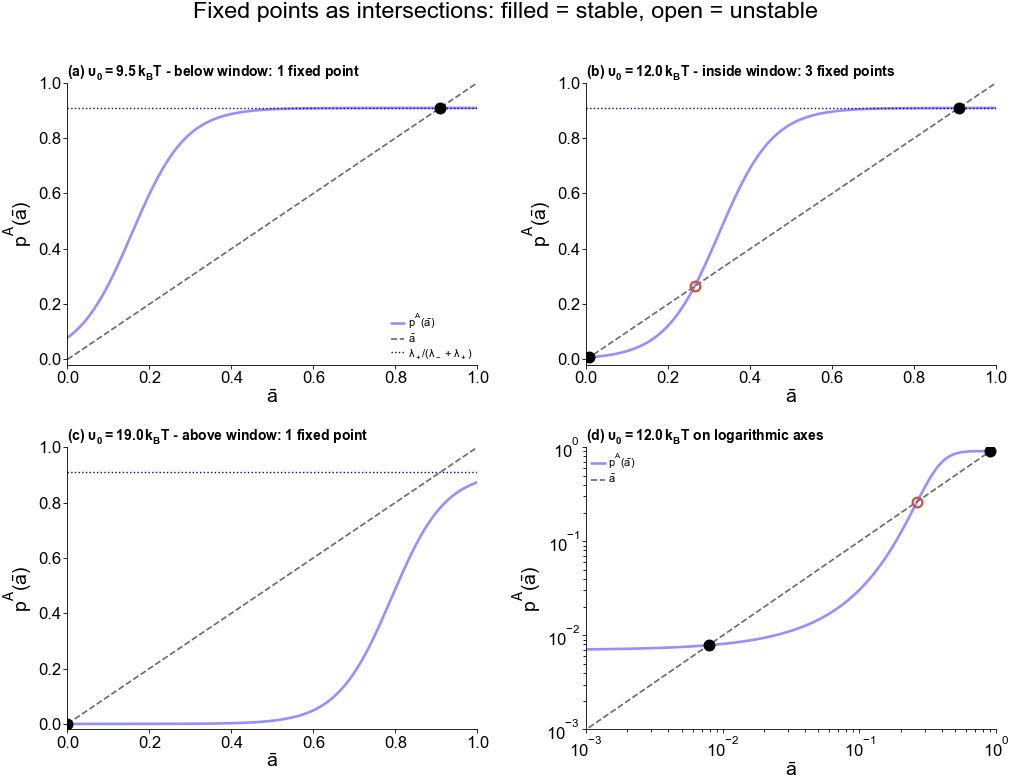

In [37]:
a_grid = np.linspace(0.0, 1.0, 2000)
A0_demo = [9.5, 12.0, 19.0]            # below / inside / above the bistable window

fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes.ravel()

for k, A0_k in enumerate(A0_demo):
    ax[k].plot(a_grid, response_of_a(a_grid, A0_k, epsilon, coef),
               color=C_RESPONSE, lw=1.9, label=r"$p^A(\bar{a})$")
    ax[k].plot(a_grid, a_grid, ls="--", color=C_DIAG, lw=1.2, label=r"$\bar{a}$")
    ax[k].axhline(coef["sup_pA"], color="navy", ls=":", lw=1.0,
                  label=r"$\lambda_+/(\lambda_-+\lambda_+)$")

    fps_k = fixed_points(A0_k, epsilon, coef)
    for fp in fps_k:
        ax[k].plot(fp["a"], fp["a"], "o", ms=7, zorder=5,
                   mfc=C_STABLE if fp["stable"] else "none",
                   mec=C_STABLE if fp["stable"] else C_UNSTABLE, mew=1.6)

    where = ["below window", "inside window", "above window"][k]
    ax[k].set_title(rf"({'abc'[k]}) $\upsilon_0={A0_k}\,k_BT$ - {where}: "
                    rf"{len(fps_k)} fixed point{'s' if len(fps_k) > 1 else ''}", fontsize=10)
    ax[k].set_xlabel(r"$\bar{a}$")
    ax[k].set_ylabel(r"$p^A(\bar{a})$")
    ax[k].set_xlim(0, 1)
    ax[k].set_ylim(-0.02, 1.0)

ax[0].legend(loc="lower right", fontsize=8)

# (d) the three-root case on logarithmic axes, where all roots are visible at once
A0_k = A0_demo[1]
ax[3].loglog(a_grid[1:], response_of_a(a_grid[1:], A0_k, epsilon, coef),
             color=C_RESPONSE, lw=1.9, label=r"$p^A(\bar{a})$")
ax[3].loglog(a_grid[1:], a_grid[1:], ls="--", color=C_DIAG, lw=1.2, label=r"$\bar{a}$")
for fp in fixed_points(A0_k, epsilon, coef):
    ax[3].plot(fp["a"], fp["a"], "o", ms=7, zorder=5,
               mfc=C_STABLE if fp["stable"] else "none",
               mec=C_STABLE if fp["stable"] else C_UNSTABLE, mew=1.6)
ax[3].set_title(rf"(d) $\upsilon_0={A0_k}\,k_BT$ on logarithmic axes", fontsize=10)
ax[3].set_xlabel(r"$\bar{a}$")
ax[3].set_ylabel(r"$p^A(\bar{a})$")
ax[3].set_xlim(1e-3, 1)
ax[3].set_ylim(1e-3, 1)
ax[3].legend(loc="upper left", fontsize=8)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle("Fixed points as intersections: filled = stable, open = unstable", y=1.00)
fig.tight_layout()
plt.show()

## 7. The gain function and the origin of the threshold

$\Psi(w)=-w\,dp^A/dw$ is the loop gain stripped of the feedback strength — the intrinsic sensitivity of the
response to the barrier. Since $dp^A/d\bar a = \beta\epsilon\Psi(w)$, the fold condition is
$\beta\epsilon\Psi(w)=1$, i.e. $\Psi(w)=1/(\beta\epsilon)$.

Reading the left panel: a horizontal line at height $1/(\beta\epsilon)$ cuts the $\Psi$ curve in **two**
points when $\epsilon>\epsilon_\mathrm{cusp}$, **tangentially** at $\epsilon=\epsilon_\mathrm{cusp}$, and
**not at all** below. That is the entire bistability criterion, and it contains no reference to
$\upsilon_0$ — this is why the fold positions in $w$ depend on $\epsilon$ alone.

$\Psi$ vanishes at both ends ($\propto w$ as $w\to0$, $\propto w^{-1}$ as $w\to\infty$), so
$\Psi_\mathrm{max}$ exists. In the fast-exchange limit $\kappa_\pm\to\infty$ the response collapses to the
logistic $p^A\to\lambda_+/(\lambda_-+\lambda_++\lambda_- v w)$, for which
$\Psi_\mathrm{max}=\lambda_+/[4(\lambda_-+\lambda_+)]$ exactly — recovering the familiar criterion
$\beta\epsilon>4(1+\lambda_-/\lambda_+)$. The factor $4$ is the signature of a logistic; the general case
replaces it by $1/\Psi_\mathrm{max}$.

In [38]:
def gain_maximum(coef, ln_w_bounds=(-25.0, 35.0)):
    # Psi_max and its location; also epsilon_cusp = 1/Psi_max (beta = 1).
    r = minimize_scalar(lambda L: -float(gain_function(np.exp(L), coef)),
                        bounds=ln_w_bounds, method="bounded",
                        options={"xatol": 1e-14})
    w_max, Psi_max = np.exp(r.x), -r.fun
    return w_max, Psi_max, 1.0 / Psi_max


w_max, Psi_max, eps_cusp = gain_maximum(coef)
Psi_max_fast = activation_rate / (4.0 * (deactivation_rate + activation_rate))

print(f"Psi_max            = {Psi_max:.8f}   at w = {w_max:.4f}  (ln w = {np.log(w_max):.4f})")
print(f"epsilon_cusp       = {eps_cusp:.6f} kT")
print(f"fast-exchange      : Psi_max = {Psi_max_fast:.8f},  epsilon_c = {1/Psi_max_fast:.6f} kT"
      f"  = 4(1+lambda_-/lambda_+)")
print(f"ratio              = {eps_cusp/(1/Psi_max_fast):.6f}"
      f"   (kappa_-/lambda_- = {coef['kappa_out']/deactivation_rate:.1f}, so close to fast exchange)")

Psi_max            = 0.22866354   at w = 1256.4552  (ln w = 7.1360)
epsilon_cusp       = 4.373238 kT
fast-exchange      : Psi_max = 0.22727273,  epsilon_c = 4.400000 kT  = 4(1+lambda_-/lambda_+)
ratio              = 0.993918   (kappa_-/lambda_- = 15000.0, so close to fast exchange)


/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_52196/1534146920.py:37: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


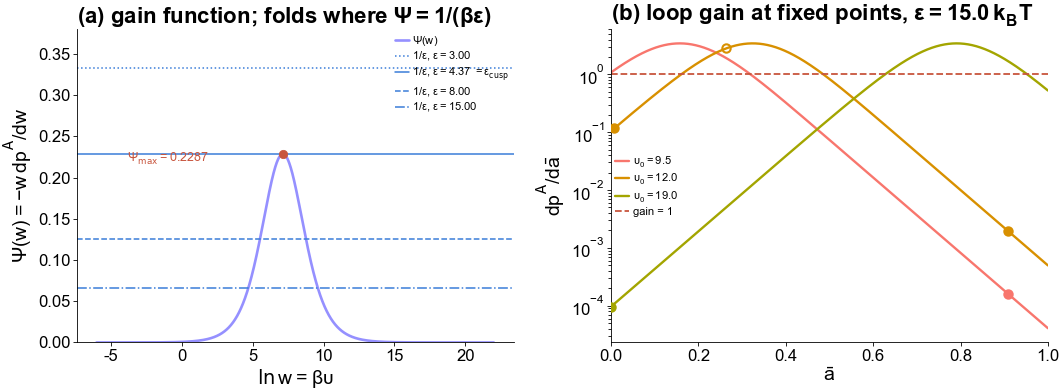

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.3))

ln_w = np.linspace(-6.0, 22.0, 3000)
ax[0].plot(ln_w, gain_function(np.exp(ln_w), coef), color=C_RESPONSE, lw=1.9, label=r"$\Psi(w)$")
ax[0].plot(np.log(w_max), Psi_max, "o", color=C_UNSTABLE, ms=6, zorder=5)
ax[0].annotate(rf"$\Psi_\mathrm{{max}}={Psi_max:.4f}$", xy=(np.log(w_max), Psi_max),
               xytext=(np.log(w_max) - 11.0, Psi_max * 0.96), fontsize=9, color=C_UNSTABLE)

for eps_k, ls in [(3.0, ":"), (eps_cusp, "-"), (8.0, "--"), (epsilon, "-.")]:
    lab = (rf"$1/\epsilon$, $\epsilon={eps_k:.2f}$"
           + (r" $=\epsilon_\mathrm{cusp}$" if abs(eps_k - eps_cusp) < 1e-9 else ""))
    ax[0].axhline(1.0 / eps_k, color=C_FOLD, ls=ls, lw=1.1, label=lab)

ax[0].set_xlabel(r"$\ln w = \beta\upsilon$")
ax[0].set_ylabel(r"$\Psi(w)=-w\,dp^A/dw$")
ax[0].set_title(r"(a) gain function; folds where $\Psi=1/(\beta\epsilon)$")
ax[0].set_ylim(0, 0.38)
ax[0].legend(fontsize=8, loc="upper right")

for k, A0_k in enumerate(A0_demo):
    ax[1].plot(a_grid, loop_gain(a_grid, A0_k, epsilon, coef),
               lw=1.7, color=colors[k], label=rf"$\upsilon_0={A0_k}$")
ax[1].axhline(1.0, color=C_UNSTABLE, ls="--", lw=1.3, label="gain = 1")
for A0_k, c in zip(A0_demo, colors[:3]):
    for fp in fixed_points(A0_k, epsilon, coef):
        ax[1].plot(fp["a"], fp["gain"], "o", ms=6, zorder=5,
                   mfc=c if fp["stable"] else "none", mec=c, mew=1.5)
ax[1].set_xlabel(r"$\bar{a}$")
ax[1].set_ylabel(r"$dp^A/d\bar{a}$")
ax[1].set_title(rf"(b) loop gain at fixed points, $\epsilon={epsilon}\,k_BT$")
ax[1].set_xlim(0, 1)
ax[1].set_yscale("log")
ax[1].legend(fontsize=8)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 8. Fold locations from a quartic; the cusp

Clearing denominators in $\beta\epsilon\Psi(w)=1$ turns the fold condition into a quartic,

$$d_2^2w^4+\big(2d_1d_2-\beta\epsilon\lambda_+c_2\big)w^3
+\big(d_1^2+2d_0d_2-\beta\epsilon\lambda_+c_1\big)w^2
+\big(2d_0d_1-\beta\epsilon\lambda_+c_0\big)w+d_0^2=0 .$$

The leading and constant coefficients, $d_2^2$ and $d_0^2$, are positive and $\epsilon$-independent; only
the middle three depend on $\epsilon$, and all decrease with it. By Descartes' rule the number of positive
roots is 0, 2 or 4 — so a 4-root case would mean two disjoint bistable windows. A scan over $\epsilon$
below checks that only the 2-root case occurs here.

Having the two roots $w_\pm$, the saddle-node points follow with **no further root finding**:

$$\beta\upsilon_0^\pm = \ln w_\pm + \beta\epsilon\,p^A(w_\pm),\qquad \bar a^\pm = p^A(w_\pm).$$

The cusp needs no quartic at all, since the two roots merge exactly at $\arg\max\Psi$:
$\epsilon_\mathrm{cusp} = 1/(\beta\Psi_\mathrm{max})$.

In [40]:
def fold_w(epsilon, coef):
    # Positive roots of the fold quartic: locations in w of the saddle-node bifurcations.
    lp = coef["activation_rate"]
    d0, d1, d2 = coef["d0"], coef["d1"], coef["d2"]
    c0, c1, c2 = coef["c0"], coef["c1"], coef["c2"]

    q = [d2**2,
         2.0 * d1 * d2 - epsilon * lp * c2,
         d1**2 + 2.0 * d0 * d2 - epsilon * lp * c1,
         2.0 * d0 * d1 - epsilon * lp * c0,
         d0**2]
    r = np.roots(q)
    pos = [z.real for z in r if abs(z.imag) < 1e-8 * max(1.0, abs(z.real)) and z.real > 0.0]
    return np.sort(pos)


def upsilon0_of_w(w, epsilon, coef):
    # Fixed-point equation solved for upsilon_0 - the explicit branch parameterisation.
    return np.log(w) + epsilon * response(w, coef)


def bistable_window(epsilon, coef):
    # (upsilon_0_low, upsilon_0_high) bounding the bistable region, or None if monostable.
    w = fold_w(epsilon, coef)
    if len(w) < 2:
        return None
    u = upsilon0_of_w(w, epsilon, coef)
    return float(np.min(u)), float(np.max(u))


def cusp_point(coef):
    w_c, Psi_m, eps_c = gain_maximum(coef)
    return dict(epsilon=eps_c, w=w_c, A0=float(upsilon0_of_w(w_c, eps_c, coef)),
                a=float(response(w_c, coef)))


cusp = cusp_point(coef)
print(f"cusp:  epsilon = {cusp['epsilon']:.6f} kT,  upsilon_0 = {cusp['A0']:.6f} kT,  "
      f"a_bar = {cusp['a']:.6f}\n")

rows = []
for eps_k in [4.0, eps_cusp, 5.0, 6.0, 8.0, 10.0, 15.0, 20.0, 30.0]:
    w = fold_w(eps_k, coef)
    win = bistable_window(eps_k, coef)
    rows.append(dict(epsilon=eps_k, n_pos_roots=len(w),
                     A0_low=np.nan if win is None else win[0],
                     A0_high=np.nan if win is None else win[1],
                     width=np.nan if win is None else win[1] - win[0],
                     a_fold_1=np.nan if len(w) < 2 else float(response(w[0], coef)),
                     a_fold_2=np.nan if len(w) < 2 else float(response(w[-1], coef)),
                     gain_check=np.nan if len(w) < 2 else eps_k * float(gain_function(w[0], coef))))
folds_tab = pd.DataFrame(rows)
print(folds_tab.to_string(index=False, float_format=lambda x: f"{x:10.6f}"))

counts = {len(fold_w(e, coef)) for e in np.linspace(eps_cusp + 1e-9, 60.0, 400)}
print(f"\npositive-root counts over epsilon in [epsilon_cusp, 60]: {counts}"
      f"  -> {'single bistable window' if counts <= {2} else 'CHECK: multiple windows'}")
assert np.allclose(folds_tab.gain_check.dropna(), 1.0), "fold roots must satisfy gain = 1"
print("all fold roots satisfy loop gain = 1 exactly.")

cusp:  epsilon = 4.373238 kT,  upsilon_0 = 9.133874 kT,  a_bar = 0.456830

   epsilon  n_pos_roots     A0_low    A0_high      width   a_fold_1   a_fold_2  gain_check
  4.000000            0        NaN        NaN        NaN        NaN        NaN         NaN
  4.373238            2   9.133874   9.133874   0.000000   0.456830   0.456830    1.000000
  5.000000            2   9.350903   9.489365   0.138462   0.618020   0.295245    1.000000
  6.000000            2   9.603382  10.149877   0.546494   0.693621   0.219115    1.000000
  8.000000            2   9.962274  11.615615   1.653341   0.762576   0.149369    1.000000
 10.000000            2  10.222668  13.178526   2.955858   0.797133   0.114258    1.000000
 15.000000            2  10.673253  17.282568   6.609315   0.838167   0.072389    1.000000
 20.000000            2  10.981911  21.525472  10.543562   0.857033   0.053076    1.000000
 30.000000            2  11.407452  30.198501  18.791048   0.875024   0.034644    1.000000

positive-root 

## 9. Bifurcation diagram

Because $\upsilon_0(w)$ is explicit, the complete $S$-curve — including the unstable middle branch — is
obtained by sweeping $w$ and plotting $\bar a = p^A(w)$ against $\upsilon_0(w)$. No continuation, no
root finding, and the unstable branch comes for free (it is the part where $\upsilon_0(w)$ runs backwards).

/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_52196/1345322883.py:47: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


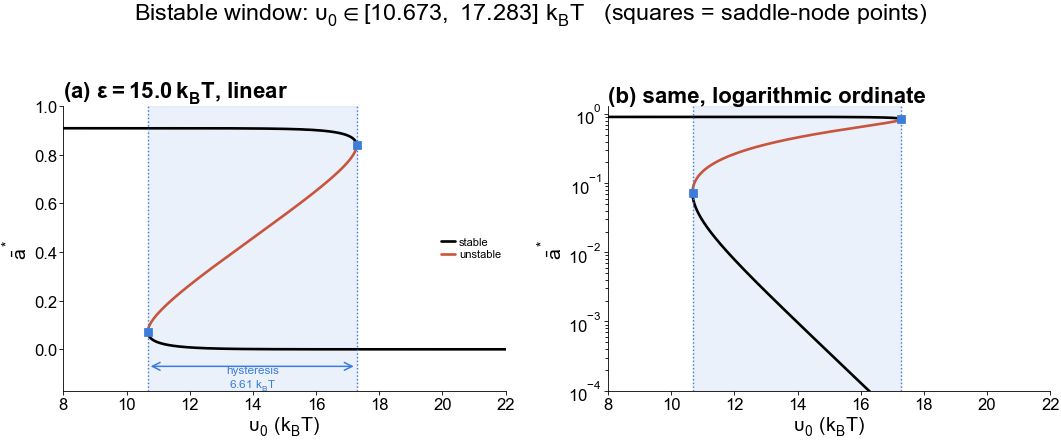

bistable window at epsilon = 15.0 kT:  upsilon_0 in [10.67325, 17.28257] kT,  width 6.60931 kT
notebook value A0 = 12.0 kT is INSIDE the window


In [41]:
def branch(epsilon, coef, ln_w=np.linspace(-20.0, 32.0, 6000)):
    # The full S-curve, parameterised by w.  Returns (upsilon_0, a_bar, stable_mask).
    w  = np.exp(ln_w)
    u0 = upsilon0_of_w(w, epsilon, coef)
    a  = response(w, coef)
    stable = epsilon * gain_function(w, coef) < 1.0
    return u0, a, stable


u0_b, a_b, st_b = branch(epsilon, coef)
win = bistable_window(epsilon, coef)
w_f = fold_w(epsilon, coef)

fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.5))
for k, logy in enumerate([False, True]):
    # NaN-masking keeps the branches as continuous parametric curves, correctly broken at the folds
    ax[k].plot(u0_b, np.where(st_b, a_b, np.nan), "-", lw=1.9, color=C_STABLE, label="stable")
    ax[k].plot(u0_b, np.where(~st_b, a_b, np.nan), "-", lw=1.9, color=C_UNSTABLE, label="unstable")

    for wf in w_f:
        ax[k].plot(upsilon0_of_w(wf, epsilon, coef), response(wf, coef),
                   "s", ms=6, color=C_FOLD, zorder=5)
    ax[k].axvline(win[0], color=C_FOLD, ls=":", lw=1.0)
    ax[k].axvline(win[1], color=C_FOLD, ls=":", lw=1.0)
    ax[k].axvspan(win[0], win[1], color=C_FOLD, alpha=0.10)

    ax[k].set_xlabel(r"$\upsilon_0\ (k_BT)$")
    ax[k].set_xlim(8, 22)
    ax[k].spines[["top", "right"]].set_visible(False)

ax[0].set_ylabel(r"$\bar{a}^*$")
ax[0].set_ylim(-0.17, 1.0)
ax[0].annotate("", xy=(win[1], -0.07), xytext=(win[0], -0.07),
               arrowprops=dict(arrowstyle="<->", color=C_FOLD, lw=1.1))
ax[0].text(0.5 * (win[0] + win[1]), -0.155,
           f"hysteresis\n{win[1]-win[0]:.2f} $k_BT$", ha="center", fontsize=8.5, color=C_FOLD)
ax[0].set_title(rf"(a) $\epsilon={epsilon}\,k_BT$, linear")
ax[0].legend(fontsize=8, loc="center right")

ax[1].set_yscale("log")
ax[1].set_ylim(1e-4, 1.3)
ax[1].set_ylabel(r"$\bar{a}^*$")
ax[1].set_title("(b) same, logarithmic ordinate")

fig.suptitle(rf"Bistable window: $\upsilon_0\in[{win[0]:.3f},\ {win[1]:.3f}]\ k_BT$"
             rf"   (squares = saddle-node points)", y=1.02)
fig.tight_layout()
plt.show()

print(f"bistable window at epsilon = {epsilon} kT:  "
      f"upsilon_0 in [{win[0]:.5f}, {win[1]:.5f}] kT,  width {win[1]-win[0]:.5f} kT")
print(f"notebook value A0 = {A0} kT is {'INSIDE' if win[0] < A0 < win[1] else 'outside'} the window")

## 10. Dynamic hysteresis sweep

The bifurcation diagram is a statement about steady states. Hysteresis is the dynamical consequence:
ramp $\upsilon_0$ slowly up and then back down, and the system tracks whichever branch it started on until
that branch disappears at a fold, then jumps.

The ramp must be slow compared with the relaxation rate. Here $R\le\lambda_-+\lambda_+=1.1\ \mathrm{s}^{-1}$,
so relaxation takes $\mathcal{O}(1\text{–}10\ \mathrm{s})$ and a ramp of
$\sim4\times10^{-3}\,k_BT\,\mathrm{s}^{-1}$ is quasi-static everywhere except immediately at the folds, where
critical slowing down ($\tau\propto|\upsilon_0-\upsilon_0^\pm|^{-1/2}$) rounds the corner slightly. That
rounding is physical, not numerical.

/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_52196/2224335897.py:53: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


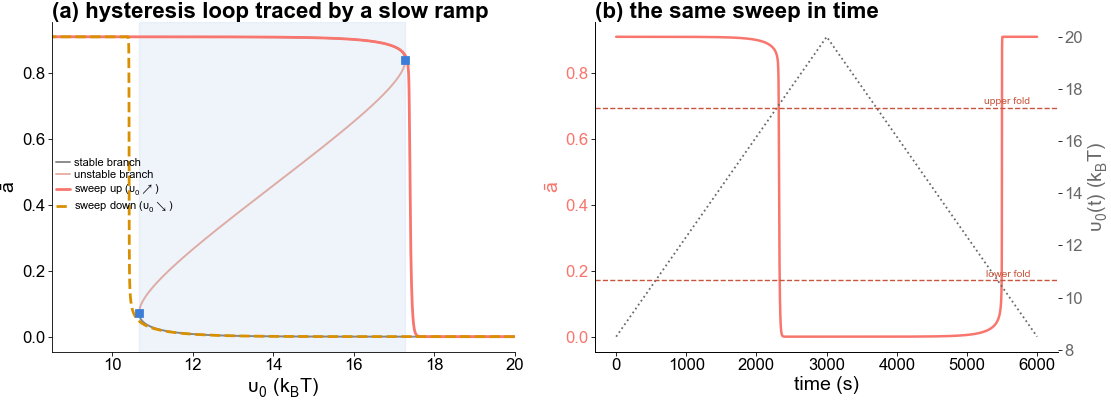

jump on the way up   at upsilon_0 = 17.392 kT   (predicted fold 17.283)
jump on the way down at upsilon_0 = 10.421 kT   (predicted fold 10.673)
-> lag of 0.109 / 0.252 kT from the finite ramp rate


In [42]:
def hysteresis_sweep(coef, epsilon, A0_min, A0_max, T_ramp=3000.0, a_init=None, n_out=4000):
    # Ramp upsilon_0 up and back down, integrating the 1D reduction throughout.
    def A0_t(t):
        return A0_min + (A0_max - A0_min) * (t / T_ramp if t <= T_ramp
                                             else 2.0 - t / T_ramp)

    if a_init is None:
        a_init = float(max(fp["a"] for fp in fixed_points(A0_min, epsilon, coef)))

    sol = solve_ivp(lambda t, y: [float(rhs(y[0], A0_t(t), epsilon, coef))],
                    (0.0, 2.0 * T_ramp), [a_init],
                    t_eval=np.linspace(0.0, 2.0 * T_ramp, n_out),
                    rtol=1e-10, atol=1e-12, max_step=5.0)

    return sol.t, np.array([A0_t(t) for t in sol.t]), sol.y[0]


t_s, A0_s, a_s = hysteresis_sweep(coef, epsilon, 8.5, 20.0)
up = t_s <= 3000.0

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))

ax[0].plot(u0_b, np.where(st_b, a_b, np.nan), "-", lw=1.4, color=C_STABLE, alpha=0.45,
           label="stable branch")
ax[0].plot(u0_b, np.where(~st_b, a_b, np.nan), "-", lw=1.4, color=C_UNSTABLE, alpha=0.45,
           label="unstable branch")
ax[0].plot(A0_s[up], a_s[up], lw=2.0, color=colors[0], label=r"sweep up ($\upsilon_0\nearrow$)")
ax[0].plot(A0_s[~up], a_s[~up], lw=2.0, color=colors[1], ls="--", label=r"sweep down ($\upsilon_0\searrow$)")
for wf in w_f:
    ax[0].plot(upsilon0_of_w(wf, epsilon, coef), response(wf, coef), "s", ms=6, color=C_FOLD, zorder=6)
ax[0].axvspan(win[0], win[1], color=C_FOLD, alpha=0.08)
ax[0].set_xlabel(r"$\upsilon_0\ (k_BT)$")
ax[0].set_ylabel(r"$\bar{a}$")
ax[0].set_xlim(8.5, 20)
ax[0].set_title("(a) hysteresis loop traced by a slow ramp")
ax[0].legend(fontsize=8, loc="center left")

ax[1].plot(t_s, a_s, lw=1.8, color=colors[0], label=r"$\bar{a}(t)$")
ax[1].set_xlabel("time (s)")
ax[1].set_ylabel(r"$\bar{a}$", color=colors[0])
ax[1].tick_params(axis="y", labelcolor=colors[0])
axt = ax[1].twinx()
axt.plot(t_s, A0_s, lw=1.3, color=C_DIAG, ls=":")
axt.set_ylabel(r"$\upsilon_0(t)\ (k_BT)$", color=C_DIAG)
axt.tick_params(axis="y", labelcolor=C_DIAG)
for wv, lab in [(win[0], "lower fold"), (win[1], "upper fold")]:
    axt.axhline(wv, color=C_UNSTABLE, lw=1.0, ls="--")
    axt.text(5900, wv + 0.12, lab, fontsize=7.5, color=C_UNSTABLE, ha="right")
ax[1].set_title("(b) the same sweep in time")

for a in ax:
    a.spines[["top"]].set_visible(False)
fig.tight_layout()
plt.show()

jump_up   = A0_s[up][np.argmax(np.abs(np.diff(a_s[up], prepend=a_s[0])))]
jump_down = A0_s[~up][np.argmax(np.abs(np.diff(a_s[~up], prepend=a_s[~up][0])))]
print(f"jump on the way up   at upsilon_0 = {jump_up:.3f} kT   (predicted fold {win[1]:.3f})")
print(f"jump on the way down at upsilon_0 = {jump_down:.3f} kT   (predicted fold {win[0]:.3f})")
print(f"-> lag of {abs(jump_up-win[1]):.3f} / {abs(jump_down-win[0]):.3f} kT from the finite ramp rate")

## 11. Effective potential landscape

For a one-dimensional system the dynamics is a gradient flow,
$\dot{\bar a} = -dV/d\bar a$ with

$$V(\bar a) = -\int_0^{\bar a} R(a')\big[p^A(a')-a'\big]\,da' .$$

Stable fixed points are minima, the unstable one is the barrier top. Sweeping $\upsilon_0$ across the
window tilts the landscape from a single well, through a genuine double well, back to a single well — the
cusp catastrophe in its most familiar form.

Note this $V$ is *not* a free energy: the dynamics is not detailed-balanced (activation happens only
outside the condensate). It is a Lyapunov function for the deterministic flow, nothing more. The
quantity that governs finite-$N$ switching rates is the stochastic quasi-potential, which is different and
needs a WKB treatment.

/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_52196/3858219937.py:69: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


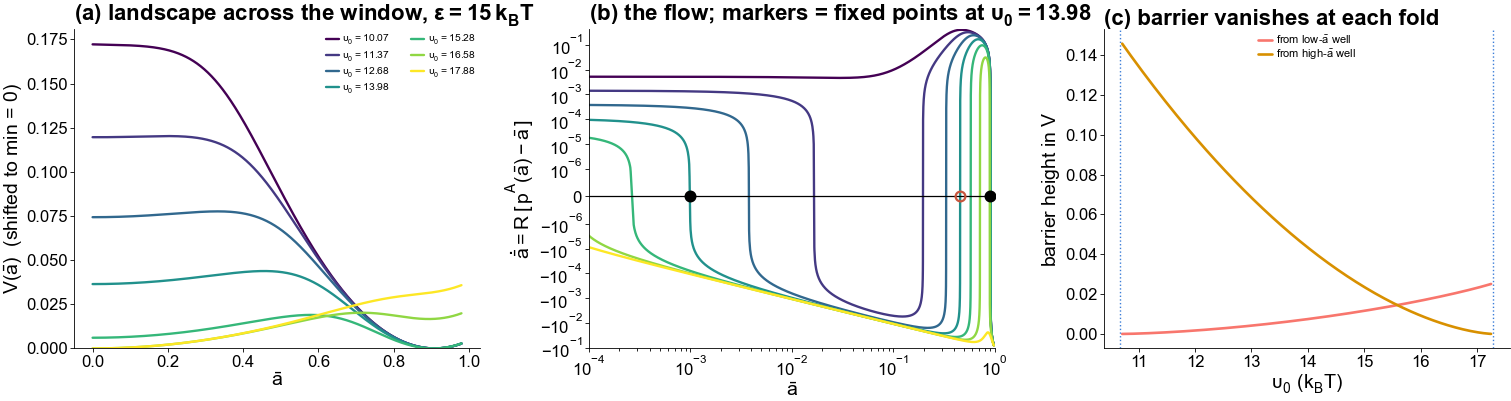

In [43]:
def effective_potential(a_grid, A0, epsilon, coef):
    # V(a) = -cumulative integral of the right-hand side.
    F = rhs(a_grid, A0, epsilon, coef)
    return -cumulative_trapezoid(F, a_grid, initial=0.0)


# Hybrid grid: the low-a_bar well sits near 1e-2 and needs logarithmic resolution
a_fine = np.unique(np.concatenate([np.logspace(-5.0, -1.0, 1200),
                                   np.linspace(0.0, 0.98, 4000)]))
A0_scan = np.linspace(win[0] - 0.6, win[1] + 0.6, 7)

fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.4))

cmap = plt.get_cmap("viridis")
for j, A0_j in enumerate(A0_scan):
    V = effective_potential(a_fine, A0_j, epsilon, coef)
    V = V - V.min()
    ax[0].plot(a_fine, V, lw=1.7, color=cmap(j / (len(A0_scan) - 1)),
               label=rf"$\upsilon_0={A0_j:.2f}$")

ax[0].set_xlabel(r"$\bar{a}$")
ax[0].set_ylabel(r"$V(\bar{a})$  (shifted to min = 0)")
ax[0].set_title(r"(a) landscape across the window, $\epsilon=15\,k_BT$")
ax[0].legend(fontsize=7.5, ncol=2)
ax[0].set_ylim(0, None)

ax[1].clear()
# The low-a_bar well is far too shallow to see in V, so show the flow itself.
# Zero crossings are the fixed points; the sign of F gives the direction of motion.
for j, A0_j in enumerate(A0_scan):
    ax[1].plot(a_fine, rhs(a_fine, A0_j, epsilon, coef), lw=1.7,
               color=cmap(j / (len(A0_scan) - 1)))
ax[1].axhline(0.0, color="k", lw=0.9)
for fp in fixed_points(float(A0_scan[3]), epsilon, coef):
    ax[1].plot(fp["a"], 0.0, "o", ms=7, zorder=5,
               mfc=C_STABLE if fp["stable"] else "none",
               mec=C_STABLE if fp["stable"] else C_UNSTABLE, mew=1.6)
ax[1].set_xscale("log")
ax[1].set_yscale("symlog", linthresh=1e-6)
ax[1].set_xlim(1e-4, 1.0)
ax[1].set_xlabel(r"$\bar{a}$")
ax[1].set_ylabel(r"$\dot{\bar{a}} = R\,[\,p^A(\bar{a})-\bar{a}\,]$")
ax[1].set_title(rf"(b) the flow; markers = fixed points at $\upsilon_0={A0_scan[3]:.2f}$")

# barrier heights, measured from each well to the unstable maximum
A0_fine = np.linspace(win[0], win[1], 200)
bar_lo, bar_hi = [], []
for A0_j in A0_fine:
    fj = fixed_points(A0_j, epsilon, coef)
    if len(fj) != 3:
        bar_lo.append(np.nan); bar_hi.append(np.nan); continue
    V = effective_potential(a_fine, A0_j, epsilon, coef)
    Vi = lambda x: np.interp(x, a_fine, V)
    lo, mid, hi = [f["a"] for f in fj]
    bar_lo.append(Vi(mid) - Vi(lo))
    bar_hi.append(Vi(mid) - Vi(hi))

ax[2].plot(A0_fine, bar_lo, lw=1.9, color=colors[0], label=r"from low-$\bar{a}$ well")
ax[2].plot(A0_fine, bar_hi, lw=1.9, color=colors[1], label=r"from high-$\bar{a}$ well")
ax[2].axvline(win[0], color=C_FOLD, ls=":", lw=1.0)
ax[2].axvline(win[1], color=C_FOLD, ls=":", lw=1.0)
ax[2].set_xlabel(r"$\upsilon_0\ (k_BT)$")
ax[2].set_ylabel(r"barrier height in $V$")
ax[2].set_title("(c) barrier vanishes at each fold")
ax[2].legend(fontsize=8)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 12. Two-parameter phase diagram and cusp scaling

Sweeping $\epsilon$ and recording the two fold values of $\upsilon_0$ traces the classic cusp wedge.
Inside it the system is bistable; outside, monostable. The cusp sits at
$\epsilon_\mathrm{cusp}=1/(\beta\Psi_\mathrm{max})$, and the wedge opens as
$\Delta\upsilon_0\propto(\epsilon-\epsilon_\mathrm{cusp})^{3/2}$ — the universal cusp-catastrophe exponent,
which the right panel confirms as a numerical check on the whole construction.

/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_52196/184900209.py:51: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


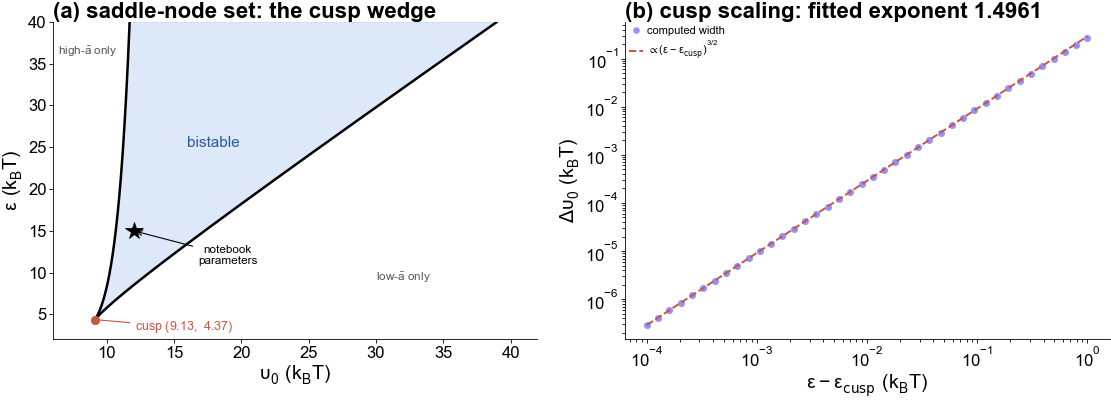

fitted cusp exponent = 1.496110  (expected 1.5)


In [44]:
eps_grid = np.concatenate([np.linspace(eps_cusp, eps_cusp + 1.0, 200)[1:],
                           np.linspace(eps_cusp + 1.0, 40.0, 500)])
lo_curve, hi_curve = [], []
for e in eps_grid:
    wnd = bistable_window(e, coef)
    lo_curve.append(np.nan if wnd is None else wnd[0])
    hi_curve.append(np.nan if wnd is None else wnd[1])
lo_curve, hi_curve = np.array(lo_curve), np.array(hi_curve)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))

ok = ~np.isnan(lo_curve)
ax[0].plot(lo_curve[ok], eps_grid[ok], color=C_STABLE, lw=1.8)
ax[0].plot(hi_curve[ok], eps_grid[ok], color=C_STABLE, lw=1.8)
ax[0].fill(np.concatenate([lo_curve[ok], hi_curve[ok][::-1]]),
           np.concatenate([eps_grid[ok], eps_grid[ok][::-1]]), color=C_FOLD, alpha=0.17)
ax[0].plot(cusp["A0"], cusp["epsilon"], "o", color=C_UNSTABLE, ms=6, zorder=5)
ax[0].annotate(rf"cusp $({cusp['A0']:.2f},\ {cusp['epsilon']:.2f})$",
               xy=(cusp["A0"], cusp["epsilon"]), xytext=(cusp["A0"] + 3.0, cusp["epsilon"] - 1.3),
               fontsize=9, color=C_UNSTABLE,
               arrowprops=dict(arrowstyle="-", color=C_UNSTABLE, lw=0.8))
ax[0].plot(A0, epsilon, "*", color="k", ms=13, zorder=6)
ax[0].annotate("notebook\nparameters", xy=(A0, epsilon), xytext=(A0 + 7.0, epsilon - 4.0),
               fontsize=8.5, ha="center", arrowprops=dict(arrowstyle="->", color="k", lw=0.8))
ax[0].text(16.0, 25.0, "bistable", color="#2a5a9c", fontsize=11)
ax[0].text(6.4, 36.0, "high-$\\bar{a}$ only", fontsize=8.5, color="#555555", ha="left")
ax[0].text(30.0, 9.0, "low-$\\bar{a}$ only", fontsize=8.5, color="#555555")
ax[0].set_xlabel(r"$\upsilon_0\ (k_BT)$")
ax[0].set_ylabel(r"$\epsilon\ (k_BT)$")
ax[0].set_title("(a) saddle-node set: the cusp wedge")
ax[0].set_xlim(6, 42)
ax[0].set_ylim(2, 40)

d_eps = np.logspace(-4.0, 0.0, 40)
widths = np.array([(lambda wd: np.nan if wd is None else wd[1] - wd[0])(
                   bistable_window(eps_cusp + d, coef)) for d in d_eps])
good = np.isfinite(widths) & (widths > 1e-12)
slope = np.polyfit(np.log(d_eps[good]), np.log(widths[good]), 1)[0]

ax[1].loglog(d_eps[good], widths[good], "o", ms=4.5, color=C_RESPONSE, label="computed width")
ref = widths[good][0] * (d_eps[good] / d_eps[good][0])**1.5
ax[1].loglog(d_eps[good], ref, "--", color=C_UNSTABLE, lw=1.4,
             label=r"$\propto(\epsilon-\epsilon_\mathrm{cusp})^{3/2}$")
ax[1].set_xlabel(r"$\epsilon-\epsilon_\mathrm{cusp}\ (k_BT)$")
ax[1].set_ylabel(r"$\Delta\upsilon_0\ (k_BT)$")
ax[1].set_title(f"(b) cusp scaling: fitted exponent {slope:.4f}")
ax[1].legend(fontsize=8)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

print(f"fitted cusp exponent = {slope:.6f}  (expected 1.5)")
assert abs(slope - 1.5) < 0.02, "cusp scaling exponent is off - check the fold quartic"

## 13. Where the interfacial correction matters

The exact response differs from the fast-exchange logistic by the term $\Gamma$ in

$$p^A=\Big[1+\Gamma+\tfrac{\lambda_-}{\lambda_+}p_\mathrm{out}^{-1}\Big]^{-1},
\qquad \Gamma=\frac{\lambda_-k_+}{k_-(\lambda_-+k_-+k_+)},$$

whose size is set by $\lambda_-/k_-$. With $k_-=\kappa_-/(1+w)$ and $\kappa_-=SD/(V_\mathrm{in}\delta)$,
this ratio grows exponentially with the barrier **and** linearly with the interface width $\delta$.

The notebook's $\delta = 0.01 = 0.1\,r_f$ gives $\kappa_-=1500\ \mathrm{s}^{-1}$, i.e.
$\kappa_-/\lambda_- = 1.5\times10^{4}$, so the system sits very close to the fast-exchange limit and
$\epsilon_\mathrm{cusp}$ is within 0.6% of $4(1+\lambda_-/\lambda_+)=4.4$. The correction becomes
significant for a thicker interface, a smaller $D$, or a larger condensate — each of which lowers
$\kappa_-$. The left panel shows the crossover.

/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_52196/749196122.py:45: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


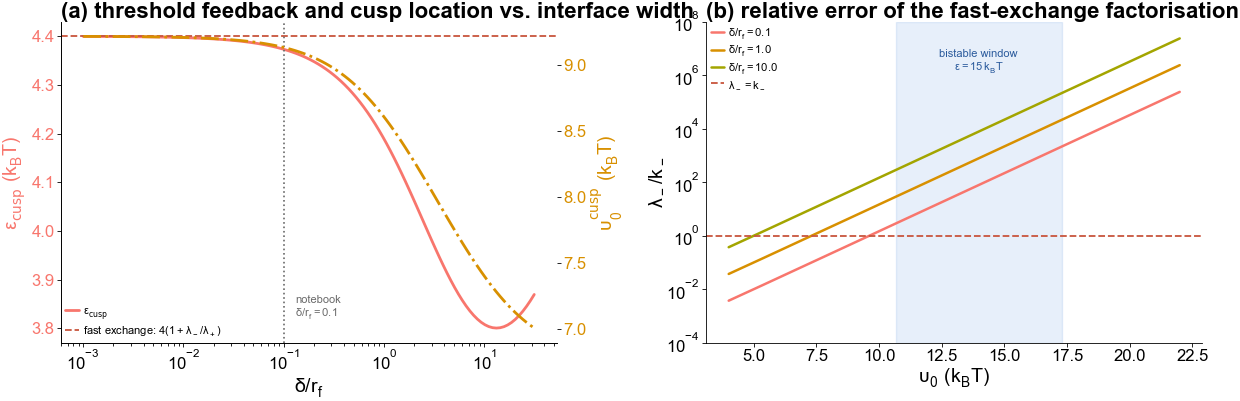

epsilon_cusp at delta/rf = 0.1  (notebook): 4.37324 kT
epsilon_cusp at delta/rf = 10            : 3.80810 kT
fast-exchange limit                      : 4.40000 kT


In [45]:
delta_over_rf = np.logspace(-3.0, 1.5, 120)
eps_c_d, A0_c_d, kappa_out_d = [], [], []
for dor in delta_over_rf:
    ck = response_coefficients(rf, rn, D, dor * rf, activation_rate, deactivation_rate)
    cp = cusp_point(ck)
    eps_c_d.append(cp["epsilon"]); A0_c_d.append(cp["A0"]); kappa_out_d.append(ck["kappa_out"])
eps_c_d, A0_c_d, kappa_out_d = map(np.array, (eps_c_d, A0_c_d, kappa_out_d))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax[0].semilogx(delta_over_rf, eps_c_d, lw=2.0, color=colors[0], label=r"$\epsilon_\mathrm{cusp}$")
ax[0].axhline(4.0 * (1.0 + deactivation_rate / activation_rate), color=C_UNSTABLE, ls="--", lw=1.3,
              label=r"fast exchange: $4(1+\lambda_-/\lambda_+)$")
ax[0].axvline(delta / rf, color=C_DIAG, ls=":", lw=1.2)
ax[0].annotate("notebook\n$\\delta/r_f=0.1$", xy=(delta / rf * 1.3, 0.08),
               xycoords=("data", "axes fraction"), fontsize=8, color=C_DIAG)
ax[0].set_xlabel(r"$\delta/r_f$")
ax[0].set_ylabel(r"$\epsilon_\mathrm{cusp}\ (k_BT)$", color=colors[0])
ax[0].tick_params(axis="y", labelcolor=colors[0])
ax[0].legend(fontsize=8, loc="lower left")
axt = ax[0].twinx()
axt.semilogx(delta_over_rf, A0_c_d, lw=2.0, color=colors[1], ls="-.")
axt.set_ylabel(r"$\upsilon_0^\mathrm{cusp}\ (k_BT)$", color=colors[1])
axt.tick_params(axis="y", labelcolor=colors[1])
ax[0].set_title("(a) threshold feedback and cusp location vs. interface width")

u0_line = np.linspace(4.0, 22.0, 400)
for j, dor in enumerate([0.1, 1.0, 10.0]):
    ck = response_coefficients(rf, rn, D, dor * rf, activation_rate, deactivation_rate)
    k_minus = ck["kappa_out"] / (1.0 + np.exp(u0_line))
    ax[1].semilogy(u0_line, deactivation_rate / k_minus, lw=1.8, color=colors[j],
                   label=rf"$\delta/r_f={dor}$")
ax[1].axhline(1.0, color=C_UNSTABLE, ls="--", lw=1.3, label=r"$\lambda_-=k_-$")
ax[1].axvspan(win[0], win[1], color=C_FOLD, alpha=0.12)
ax[1].text(0.5 * (win[0] + win[1]), 1.5e6, "bistable window\n$\\epsilon=15\\,k_BT$",
           ha="center", fontsize=8, color="#2a5a9c")
ax[1].set_xlabel(r"$\upsilon_0\ (k_BT)$")
ax[1].set_ylabel(r"$\lambda_-/k_-$")
ax[1].set_title("(b) relative error of the fast-exchange factorisation")
ax[1].set_ylim(1e-4, 1e8)
ax[1].legend(fontsize=8, loc="upper left")

for a in ax:
    a.spines[["top"]].set_visible(False)
fig.tight_layout()
plt.show()

print(f"epsilon_cusp at delta/rf = 0.1  (notebook): {cusp['epsilon']:.5f} kT")
print(f"epsilon_cusp at delta/rf = 10            : "
      f"{cusp_point(response_coefficients(rf, rn, D, 10*rf, activation_rate, deactivation_rate))['epsilon']:.5f} kT")
print(f"fast-exchange limit                      : {4*(1+deactivation_rate/activation_rate):.5f} kT")

## 14. Relaxation to the two attractors

Two final checks. Panel (a) integrates the 1D reduction from a spread of initial conditions at
$\upsilon_0=12\,k_BT$: every trajectory starting below the unstable fixed point falls to the low state,
every one above rises to the high state. The unstable point is the separatrix.

Panel (b) tests the reduction itself. The 1D equation assumes the spatial distribution *within* the active
population is slaved to $\bar a$ — legitimate when $\lambda_\pm\ll k_-+k_+$. Integrating the full
four-state mean-field system **with feedback**, starting from a state where the reduction's assumption is
deliberately violated (equal active fractions inside and outside), shows how quickly the reduction
becomes accurate and whether it picks the same attractor.

a_0 = 0.2:  1D endpoint = 0.00785664,  4-state endpoint = 0.00786050,  difference = 3.86e-06
a_0 = 0.32:  1D endpoint = 0.90896081,  4-state endpoint = 0.90896081,  difference = 9.66e-12


/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_52196/1976135324.py:62: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


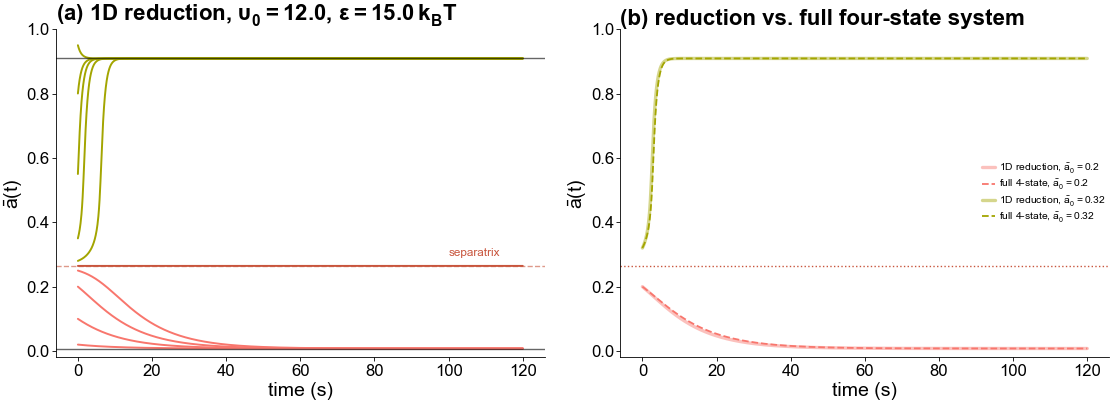

In [46]:
def four_state_feedback(t, y, A0, epsilon, coef):
    # Full mean-field master equation with upsilon = upsilon_0 - epsilon * (p_in^A + p_out^A).
    p_in_A, p_in_N, p_out_A, p_out_N = y
    w = w_of_a(p_in_A + p_out_A, A0, epsilon)
    k_in  = coef["kappa_in"] * w / (1.0 + w)
    k_out = coef["kappa_out"] / (1.0 + w)
    lp, lm = coef["activation_rate"], coef["deactivation_rate"]

    return [k_in * p_out_A - (lm + k_out) * p_in_A,
            k_in * p_out_N + lm * p_in_A - k_out * p_in_N,
            k_out * p_in_A + lp * p_out_N - (lm + k_in) * p_out_A,
            k_out * p_in_N + lm * p_out_A - (lp + k_in) * p_out_N]


fps_12 = fixed_points(A0, epsilon, coef)
a_sep  = [f["a"] for f in fps_12 if not f["stable"]][0]
t_eval = np.linspace(0.0, 120.0, 1500)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))

for a_init in [0.02, 0.10, 0.20, 0.25, a_sep, 0.28, 0.35, 0.55, 0.80, 0.95]:
    sol = solve_ivp(lambda t, y: [float(rhs(y[0], A0, epsilon, coef))],
                    (0.0, t_eval[-1]), [a_init], t_eval=t_eval, rtol=1e-10, atol=1e-12)
    ax[0].plot(sol.t, sol.y[0], lw=1.4,
               color=C_UNSTABLE if abs(a_init - a_sep) < 1e-12 else
                     (colors[0] if a_init < a_sep else colors[2]))

for f in fps_12:
    ax[0].axhline(f["a"], color=C_STABLE if f["stable"] else C_UNSTABLE,
                  ls="-" if f["stable"] else "--", lw=1.0, alpha=0.6)
ax[0].text(100, a_sep + 0.03, "separatrix", color=C_UNSTABLE, fontsize=8.5)
ax[0].set_xlabel("time (s)")
ax[0].set_ylabel(r"$\bar{a}(t)$")
ax[0].set_title(rf"(a) 1D reduction, $\upsilon_0={A0}$, $\epsilon={epsilon}\,k_BT$")
ax[0].set_ylim(-0.02, 1.0)

for a_init, c in [(0.20, colors[0]), (0.32, colors[2])]:
    sol1 = solve_ivp(lambda t, y: [float(rhs(y[0], A0, epsilon, coef))],
                     (0.0, t_eval[-1]), [a_init], t_eval=t_eval, rtol=1e-10, atol=1e-12)
    p_out0 = 1.0 / (1.0 + coef["v"] * np.exp(A0 - epsilon * a_init))
    y0 = [a_init * (1 - p_out0), (1 - a_init) * (1 - p_out0),
          a_init * p_out0,       (1 - a_init) * p_out0]
    sol4 = solve_ivp(four_state_feedback, (0.0, t_eval[-1]), y0, t_eval=t_eval,
                     args=(A0, epsilon, coef), method="LSODA", rtol=1e-10, atol=1e-12)
    ax[1].plot(sol1.t, sol1.y[0], lw=2.4, color=c, alpha=0.45,
               label=rf"1D reduction, $\bar{{a}}_0={a_init}$")
    ax[1].plot(sol4.t, sol4.y[0] + sol4.y[2], lw=1.3, ls="--", color=c,
               label=rf"full 4-state, $\bar{{a}}_0={a_init}$")
    print(f"a_0 = {a_init}:  1D endpoint = {sol1.y[0][-1]:.8f},  "
          f"4-state endpoint = {sol4.y[0][-1]+sol4.y[2][-1]:.8f},  "
          f"difference = {abs(sol1.y[0][-1]-(sol4.y[0][-1]+sol4.y[2][-1])):.2e}")

ax[1].axhline(a_sep, color=C_UNSTABLE, ls=":", lw=1.0)
ax[1].set_xlabel("time (s)")
ax[1].set_ylabel(r"$\bar{a}(t)$")
ax[1].set_title("(b) reduction vs. full four-state system")
ax[1].legend(fontsize=7.5)
ax[1].set_ylim(-0.02, 1.0)

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 15. Summary

In [47]:
summary = pd.DataFrame([
    ("v = V_in/V_out",                       coef["v"],              "-"),
    ("kappa_+ (entry ceiling)",              coef["kappa_in"],       "1/s"),
    ("kappa_- (exit ceiling)",               coef["kappa_out"],      "1/s"),
    ("kappa_-/lambda_-",                     coef["kappa_out"] / deactivation_rate, "-"),
    ("plateau sup p^A",                      coef["sup_pA"],         "-"),
    ("Psi_max",                              Psi_max,                "-"),
    ("epsilon_cusp = 1/Psi_max",             eps_cusp,               "k_B T"),
    ("  fast-exchange 4(1+lam-/lam+)",       4 * (1 + deactivation_rate / activation_rate), "k_B T"),
    ("upsilon_0 at cusp",                    cusp["A0"],             "k_B T"),
    ("a_bar at cusp",                        cusp["a"],              "-"),
    ("window lower fold (eps=15)",           win[0],                 "k_B T"),
    ("window upper fold (eps=15)",           win[1],                 "k_B T"),
    ("hysteresis width (eps=15)",            win[1] - win[0],        "k_B T"),
    ("separatrix at A0=12, eps=15",          a_sep,                  "-"),
], columns=["quantity", "value", "units"])

print(summary.to_string(index=False, float_format=lambda x: f"{x:14.6f}"))
print()
print(f"Bistability requires epsilon > {eps_cusp:.4f} k_B T.")
print(f"At epsilon = {epsilon} k_B T the window is upsilon_0 in [{win[0]:.3f}, {win[1]:.3f}] k_B T.")
print(f"The notebook value A0 = {A0} k_B T lies inside it, with stable states at "
      f"a_bar = {min(f['a'] for f in fps_12):.5f} and {max(f['a'] for f in fps_12):.5f}.")

                      quantity          value units
                v = V_in/V_out       0.008065     -
       kappa_+ (entry ceiling)      12.096774   1/s
        kappa_- (exit ceiling)    1500.000000   1/s
              kappa_-/lambda_-   15000.000000     -
               plateau sup p^A       0.909091     -
                       Psi_max       0.228664     -
      epsilon_cusp = 1/Psi_max       4.373238 k_B T
  fast-exchange 4(1+lam-/lam+)       4.400000 k_B T
             upsilon_0 at cusp       9.133874 k_B T
                 a_bar at cusp       0.456830     -
    window lower fold (eps=15)      10.673253 k_B T
    window upper fold (eps=15)      17.282568 k_B T
     hysteresis width (eps=15)       6.609315 k_B T
   separatrix at A0=12, eps=15       0.264444     -

Bistability requires epsilon > 4.3732 k_B T.
At epsilon = 15.0 k_B T the window is upsilon_0 in [10.673, 17.283] k_B T.
The notebook value A0 = 12.0 k_B T lies inside it, with stable states at a_bar = 0.00785 and 0.9089

### How to reuse this

Everything is driven by `coef = response_coefficients(...)`. To analyse a different parameter set, rebuild
that dictionary and the rest follows:

```python
coef = response_coefficients(rf, rn, D, delta, activation_rate, deactivation_rate)
w_c, Psi_max, eps_cusp = gain_maximum(coef)     # threshold feedback strength
win = bistable_window(epsilon, coef)            # fold values of upsilon_0
u0, a, stable = branch(epsilon, coef)           # full S-curve, ready to plot
fps = fixed_points(A0, epsilon, coef)           # roots with stability flags
```

**Next steps, in order of what the analysis has made ready:**

1. **Finite-$N$ stochastics.** The deterministic skeleton is now fixed: two attractors and the separatrix
   at $\bar a\approx0.26$. Gillespie simulations of $N$ particles should show switching times growing as
   $e^{N\Delta\phi}$, with $\Delta\phi$ the quasi-potential — *not* the barrier in $V$ from Section 11,
   since the dynamics is not detailed-balanced.
2. **Parameter realism.** $\epsilon_\mathrm{cusp}\approx4.4\,k_BT$ is far below the $15\,k_BT$ currently
   used, so bistability survives at much more defensible coupling strengths. Worth re-running Figure 2 of
   the manuscript at $\epsilon\sim5$–$7\,k_BT$ and reporting the corresponding partition coefficients.
3. **The oscillator.** The $S$-curve computed by `branch` **is** the $\bar a$-nullcline of the two-variable
   system in Section 6 of the manuscript. Adding the slow variable $z$ with
   $\upsilon=\upsilon_0-\epsilon\bar a+\eta z$ shifts it horizontally, so the $z$-nullcline
   $z=(\lambda_z/\delta_z)\bar a$ crossing the **unstable middle branch** is exactly the condition for a
   relaxation oscillation, and the fold points found here become the jump points of the limit cycle. The
   Hopf boundary follows from the Jacobian with $F_{\bar a}=R\,(dp^A/d\bar a-1)$ evaluated on that branch.